<a href="https://colab.research.google.com/github/joseph-2412/fisica-computacional-2026-02/blob/main/Taller_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Parte B: constante de Wien

In [44]:
%%writefile modulo_ceros.f90
module modulo_ceros
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  real(dp), parameter :: h_planck = 6.62607015e-34_dp
  real(dp), parameter :: c_luz    = 2.99792458e8_dp
  real(dp), parameter :: k_boltz  = 1.380649e-23_dp
  integer :: n_actual = 5

contains

  real(dp) function f_wien(x)
    real(dp), intent(in) :: x
    f_wien = x - real(n_actual, dp) * (1.0_dp - exp(-x))
  end function f_wien

  real(dp) function df_wien(x)
    real(dp), intent(in) :: x
    df_wien = 1.0_dp - real(n_actual, dp) * exp(-x)
  end function df_wien

  subroutine biseccion(a_in, b_in, tol, raiz, iter, u_hist, guardar)
    real(dp), intent(in)  :: a_in, b_in, tol
    real(dp), intent(out) :: raiz
    integer, intent(out)  :: iter
    integer, intent(in)   :: u_hist
    logical, intent(in)   :: guardar
    real(dp) :: a, b, c
    integer  :: k

    a = a_in
    b = b_in
    do k = 1, 100
       c = 0.5_dp * (a + b)
       if (guardar) write(u_hist, '(i2, 2x, i4, 2x, es24.16)') 1, k, c
       if (0.5_dp * (b - a) < tol) exit
       if (f_wien(a) * f_wien(c) <= 0.0_dp) then
          b = c
       else
          a = c
       end if
    end do
    raiz = c
    iter = k
  end subroutine biseccion

  subroutine newton(x0, tol, raiz, iter, u_hist, guardar)
    real(dp), intent(in)  :: x0, tol
    real(dp), intent(out) :: raiz
    integer, intent(out)  :: iter
    integer, intent(in)   :: u_hist
    logical, intent(in)   :: guardar
    real(dp) :: x, x_new
    integer  :: k

    x = x0
    do k = 1, 100
       x_new = x - f_wien(x) / df_wien(x)
       if (guardar) write(u_hist, '(i2, 2x, i4, 2x, es24.16)') 2, k, x_new
       if (abs(x_new - x) < tol) exit
       x = x_new
    end do
    raiz = x_new
    iter = k
  end subroutine newton

  subroutine secante(x0_in, x1_in, tol, raiz, iter, u_hist, guardar)
    real(dp), intent(in)  :: x0_in, x1_in, tol
    real(dp), intent(out) :: raiz
    integer, intent(out)  :: iter
    integer, intent(in)   :: u_hist
    logical, intent(in)   :: guardar
    real(dp) :: x0, x1, x_new
    integer  :: k

    x0 = x0_in
    x1 = x1_in
    do k = 1, 100
       x_new = x1 - f_wien(x1) * (x1 - x0) / (f_wien(x1) - f_wien(x0))
       if (guardar) write(u_hist, '(i2, 2x, i4, 2x, es24.16)') 3, k, x_new
       if (abs(x_new - x1) < tol) exit
       x0 = x1
       x1 = x_new
    end do
    raiz = x_new
    iter = k
  end subroutine secante

end module modulo_ceros

Writing modulo_ceros.f90


In [45]:
%%writefile programa_wien.f90
program programa_wien
  use modulo_ceros
  implicit none
  real(dp), parameter :: tol = 1.0e-10_dp
  real(dp) :: r_bis, r_new, r_sec, r_triv, x5, x3, b_wien
  integer  :: it_bis, it_new, it_sec, it_triv, n_val, u_res, u_hist, u_const
  logical  :: guardar

  open(newunit=u_res, file='resultado_wien.dat', status='replace', action='write')
  open(newunit=u_hist, file='iteraciones_wien.dat', status='replace', action='write')

  do n_val = 5, 3, -2
     n_actual = n_val
     guardar = (n_val == 5)

     call biseccion(1.0_dp, 10.0_dp, tol, r_bis, it_bis, u_hist, guardar)
     call newton(10.0_dp, tol, r_new, it_new, u_hist, guardar)
     call secante(10.0_dp, 9.0_dp, tol, r_sec, it_sec, u_hist, guardar)

     write(u_res, '(i2, 2x, i2, 2x, es24.16, 2x, i4)') n_val, 1, r_bis, it_bis
     write(u_res, '(i2, 2x, i2, 2x, es24.16, 2x, i4)') n_val, 2, r_new, it_new
     write(u_res, '(i2, 2x, i2, 2x, es24.16, 2x, i4)') n_val, 3, r_sec, it_sec

     if (n_val == 5) x5 = r_new
     if (n_val == 3) x3 = r_new
  end do

  ! Fila 7: n = 5, metodo = 4 (Newton desde x0 = 0.5 -> raiz trivial)
  n_actual = 5
  call newton(0.5_dp, tol, r_triv, it_triv, u_hist, .false.)
  write(u_res, '(i2, 2x, i2, 2x, es24.16, 2x, i4)') 5, 4, r_triv, it_triv

  close(u_res)
  close(u_hist)

  b_wien = (h_planck * c_luz) / (k_boltz * x5)
  open(newunit=u_const, file='constante_wien.dat', status='replace', action='write')
  write(u_const, '(3(es24.16, 2x))') x5, x3, b_wien
  close(u_const)

  print '(a, f18.14)', 'x5 = ', x5
  print '(a, f18.14)', 'x3 = ', x3
  print '(a, es18.10)', 'b  = ', b_wien
end program programa_wien

Writing programa_wien.f90


In [46]:
%%bash
gfortran -O2 -Wall -fcheck=bounds modulo_ceros.f90 programa_wien.f90 -o programa_wien
./programa_wien

x5 =   4.96511423174428
x3 =   2.82143937212208
b  =   2.8977719552E-03


##Parte C: constante de Stefan-Boltzmann

In [47]:
%%writefile modulo_romberg.f90
module modulo_romberg
  implicit none
  integer, parameter  :: dp = kind(1.0d0)
  real(dp), parameter :: h_planck = 6.62607015e-34_dp
  real(dp), parameter :: c_luz    = 2.99792458e8_dp
  real(dp), parameter :: k_boltz  = 1.380649e-23_dp

contains

  subroutine romberg(func, a, b, tol, max_k, res, k_final)
    interface
       real(dp) function func(x)
         import :: dp
         real(dp), intent(in) :: x
       end function func
    end interface
    real(dp), intent(in)  :: a, b, tol
    integer, intent(in)   :: max_k
    real(dp), intent(out) :: res
    integer, intent(out)  :: k_final

    real(dp) :: R(0:max_k, 0:max_k)
    real(dp) :: h, suma, x
    integer  :: k, j, i, n_sub

    h = b - a
    R(0, 0) = 0.5_dp * h * (func(a) + func(b))
    k_final = 0
    res = R(0, 0)

    do k = 1, max_k
       n_sub = 2**(k - 1)
       h = (b - a) / real(2**k, dp)
       suma = 0.0_dp

       do i = 1, n_sub
          x = a + real(2*i - 1, dp) * h
          suma = suma + func(x)
       end do

       R(k, 0) = 0.5_dp * R(k - 1, 0) + h * suma

       do j = 1, k
          R(k, j) = R(k, j - 1) + (R(k, j - 1) - R(k - 1, j - 1)) / (4.0_dp**j - 1.0_dp)
       end do

       k_final = k
       res = R(k, k)

       if (abs(R(k, k) - R(k - 1, k - 1)) < tol) exit
    end do
  end subroutine romberg

  real(dp) function integrando_t(t)
    real(dp), intent(in) :: t
    real(dp) :: x

    if (t <= 0.0_dp .or. t >= 1.0_dp) then
       integrando_t = 0.0_dp
       return
    end if

    x = t / (1.0_dp - t)
    if (x > 60.0_dp) then
       integrando_t = 0.0_dp
       return
    end if

    integrando_t = ((x**3) / (exp(x) - 1.0_dp)) / ((1.0_dp - t)**2)
  end function integrando_t

  real(dp) function integrando_x(x)
    real(dp), intent(in) :: x

    if (x <= 0.0_dp) then
       integrando_x = 0.0_dp
       return
    end if

    integrando_x = (x**3) / (exp(x) - 1.0_dp)
  end function integrando_x

end module modulo_romberg

Overwriting modulo_romberg.f90


In [48]:
%%writefile programa_sigma.f90
program programa_sigma
  use modulo_romberg
  implicit none
  real(dp), parameter :: pi = acos(-1.0_dp)
  real(dp), parameter :: tol = 1.0e-10_dp
  integer, parameter  :: max_k = 15

  real(dp) :: I_cambio, I_directa, sigma_1, sigma_2, factor
  integer  :: k1, k2, u

  factor = 2.0_dp * pi * (k_boltz**4) / ((h_planck**3) * (c_luz**2))

  call romberg(integrando_t, 0.0_dp, 1.0_dp, tol, max_k, I_cambio, k1)
  sigma_1 = factor * I_cambio

  call romberg(integrando_x, 0.0_dp, 100.0_dp, tol, max_k, I_directa, k2)
  sigma_2 = factor * I_directa

  open(newunit=u, file='resultado_sigma.dat', status='replace', action='write')
  write(u, '(i4, 2x, i8, 2x, es24.16, 2x, es24.16)') k1, 2**k1 + 1, I_cambio, sigma_1
  write(u, '(i4, 2x, i8, 2x, es24.16, 2x, es24.16)') k2, 2**k2 + 1, I_directa, sigma_2
  close(u)

  print '(a, i2, a, es18.10)', 'Fila 1 (k=', k1, '): sigma = ', sigma_1
  print '(a, i2, a, es18.10)', 'Fila 2 (k=', k2, '): I     = ', I_directa
end program programa_sigma

Overwriting programa_sigma.f90


In [49]:
%%bash
gfortran -O2 -Wall -fcheck=bounds modulo_romberg.f90 programa_sigma.f90 -o programa_sigma
./programa_sigma

Fila 1 (k=10): sigma =   5.6703744192E-08
Fila 2 (k= 1): I     =   1.6072915400E-15


##Parte D: máximo del espectro solar

In [50]:
%%writefile maximo_espectro.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq

h_planck = 6.62607015e-34
c_luz    = 2.99792458e8
k_boltz  = 1.380649e-23
T_sol    = 5772.0

def planck_lambda(lam_nm, T):
    lam_m = lam_nm * 1e-9
    x = (h_planck * c_luz) / (lam_m * k_boltz * T)
    B_m = (2.0 * h_planck * c_luz**2) / (lam_m**5 * np.expm1(x))
    return B_m * 1e-9

def filtrar_maximo(raices, segunda_deriv, lam_ref, a, b):
    validas = [
        r for r in raices
        if np.isfinite(r) and (a <= r <= b) and (segunda_deriv(r) < 0.0)
    ]
    if not validas:
        return np.nan
    return min(validas, key=lambda r: abs(r - lam_ref))

# Leer x5, x3, b_wien desde constante_wien.dat
datos_wien = np.loadtxt('constante_wien.dat')
x5, x3, b_wien = datos_wien[0], datos_wien[1], datos_wien[2]

lam_teorico = (b_wien / T_sol) * 1e9
lam_max_frec = (h_planck * c_luz / (k_boltz * T_sol * x3)) * 1e9

pasos = [100.0, 50.0, 25.0, 12.5]
resultados_dat = []
datos_25 = None

for dlam in pasos:
    lam = np.arange(100.0, 3000.0 + 0.5 * dlam, dlam)
    B = planck_lambda(lam, T_sol)

    # (a) maximo discreto
    lam_a = lam[np.argmax(B)]

    # (b) cero del spline de la derivada central
    dB_central = (B[2:] - B[:-2]) / (2.0 * dlam)
    lam_int = lam[1:-1]
    cs_deriv_central = CubicSpline(lam_int, dB_central)
    raices_b = cs_deriv_central.roots(extrapolate=False)
    lam_b = filtrar_maximo(raices_b, cs_deriv_central.derivative(1), lam_a, lam[0], lam[-1])

    # (c) cero de la derivada del spline de B_lambda
    cs_B = CubicSpline(lam, B)
    d1_cs_B = cs_B.derivative(1)
    d2_cs_B = cs_B.derivative(2)
    raices_c = d1_cs_B.roots(extrapolate=False)
    lam_c = filtrar_maximo(raices_c, d2_cs_B, lam_a, lam[0], lam[-1])

    err_a = abs(lam_a - lam_teorico)
    err_b = abs(lam_b - lam_teorico)
    err_c = abs(lam_c - lam_teorico)

    resultados_dat.append((dlam, err_a, err_b, err_c))

    if np.isclose(dlam, 25.0):
        datos_25 = (lam, B, cs_B, lam_c)

with open('maximo_espectro.dat', 'w', encoding='utf-8') as f:
    f.write("# d_lam(nm)  err_a(nm)  err_b(nm)  err_c(nm)\n")
    for fila in resultados_dat:
        f.write(f"{fila[0]:8.2f}  {fila[1]:14.8f}  {fila[2]:14.8f}  {fila[3]:14.8f}\n")

lam_25, B_25, cs_B_25, lam_max_25 = datos_25
lam_fino = np.linspace(100.0, 3000.0, 1000)

plt.figure(figsize=(10, 5.5), dpi=150)
plt.plot(lam_fino, cs_B_25(lam_fino), color='#1f77b4', lw=2, label='CubicSpline ($\\Delta\\lambda = 25$ nm)')
plt.scatter(lam_25, B_25, color='black', s=14, zorder=3, alpha=0.7, label='Datos muestreados ($\\Delta\\lambda = 25$ nm)')

B_pico = float(cs_B_25(lam_max_25))
plt.axvline(lam_max_25, color='#d62728', linestyle='--', lw=1.6,
            label=f'$\\lambda_{{\\max}}$ (espectro $B_\\lambda$) = {lam_max_25:.2f} nm')
plt.scatter([lam_max_25], [B_pico], color='#d62728', s=60, zorder=4)

B_en_frec = float(cs_B_25(lam_max_frec))
plt.axvline(lam_max_frec, color='#2ca02c', linestyle='-.', lw=1.6,
            label=f'$\\lambda(\\nu_{{\\max}}) = hc/(k_B T x_3)$ = {lam_max_frec:.2f} nm')
plt.scatter([lam_max_frec], [B_en_frec], color='#2ca02c', s=60, zorder=4)

plt.title('Espectro de cuerpo negro solar ($T = 5772$ K)', fontsize=12)
plt.xlabel('Longitud de onda $\\lambda$ (nm)', fontsize=11)
plt.ylabel('Radiancia espectral $B_\\lambda$ ($\\mathrm{W \\cdot m^{-2} \\cdot sr^{-1} \\cdot nm^{-1}}$)', fontsize=11)
plt.xlim(100, 3000)
plt.ylim(bottom=0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, fontsize=9.5)
plt.tight_layout()
plt.savefig('espectro_solar.png')

Overwriting maximo_espectro.py


In [51]:
!python maximo_espectro.py

## ÁRTE E
E. Preguntas de interpretación

###1. Costo de los métodos y orden de convergencia ($n = 5$)

Para resolver la ecuación con tolerancia $10^{-10}$, bisección necesita 37 iteraciones, Newton-Raphson 4 y secante 5. En evaluaciones de función, realizan 37, 8 y 7, respectivamente.

Calculando el orden de convergencia con los errores de "iteraciones_wien.dat":

- Newton: se obtiene $p \approx 2.00$, lo que confirma su convergencia cuadrática.
- Secante: se obtiene $p \approx 1.64$, cercano al valor teórico de $1.618$.

Newton resulta ser el método más rápido en este caso.

###2. Valor inicial ($x_0 = 0.5$)

Al iniciar Newton-Raphson en $x_0 = 0.5$, el método converge a $x = 0$. Esta raíz es matemáticamente válida porque $f(0) = 0$ y $f'(0) = -4$.

Sin embargo, físicamente no es una solución útil, ya que $x = 0$ corresponde a $\lambda \to \infty$, donde la radiancia tiende a cero y no alcanza un máximo.

###3. Parada prematura en $[0, 100]$

Romberg se detiene en $k = 1$ y devuelve aproximadamente $1.61\times10^{-15}$. El problema es que en las primeras evaluaciones no alcanza a detectar el pico de la función, ubicado cerca de $x \approx 2.82$.

Como la diferencia entre las aproximaciones es menor que $10^{-10}$, el programa se detiene antes de tiempo. Una solución sería exigir un mínimo de subdivisiones, por ejemplo $k \geq 6$, antes de comprobar la tolerancia.

###4. Eslabón más débil en el espectro solar

En el método (b), al reducir a la mitad $\Delta\lambda$, el error disminuye aproximadamente por un factor de 4. Esto se debe a que las diferencias finitas centrales tienen un error de orden $O(\Delta\lambda^2)$, que limita la precisión del spline.

En el método (c), el error disminuye mucho más porque se deriva directamente el spline. En cambio, el error del método (a) permanece en $2.0395\text{ nm}$, ya que el punto de la malla más cercano al máximo siempre es $500\text{ nm}$.

###5. Dos máximos y el color del Sol

Los máximos no coinciden: para longitud de onda se obtiene $502.04\text{ nm}$ y para frecuencia $883.48\text{ nm}$. Esto ocurre porque $B_\lambda$ y $B_\nu$ representan la radiación de forma diferente y el cambio de variable introduce el factor $c/\lambda^2$.

El color del Sol no depende de uno de estos máximos, sino de toda la radiación que llega al ojo en el rango visible ($380$–$750\text{ nm}$). Por eso, a una temperatura de $5772\text{ K}$, la luz solar se percibe blanca, aunque la atmósfera puede darle un tono amarillento.

In [52]:
# ==================== VERIFICACIÓN DEL TALLER 8 Y 9 (no modificar) ====================
import os
import numpy as np
from scipy.interpolate import CubicSpline as _CS

H_, C_, KB_ = 6.62607015e-34, 299792458.0, 1.380649e-23

def raiz_referencia(n):
    x = float(n)
    for _ in range(200):
        x = n*(1 - np.exp(-x))
    return x

X5, X3 = raiz_referencia(5), raiz_referencia(3)
B_REF = H_*C_/(KB_*X5)
I_REF = np.pi**4/15
S_REF = 2*np.pi*KB_**4/(H_**3*C_**2)*I_REF
ITER_ESPERADAS = {(5,1):37, (5,2):4, (5,3):5,
                  (3,1):37, (3,2):5, (3,3):6}

_avisados = set()
def tabla(dat, fuentes, forma=None):
    for ruta in [dat, *fuentes]:
        if not os.path.isfile(ruta):
            raise ValueError(f"no existe {ruta}; ejecute desde la carpeta del taller")
    antiguos = [f for f in fuentes if os.path.getmtime(dat) < os.path.getmtime(f)]
    if antiguos and dat not in _avisados:
        print(f"[AVISO] {dat} parece anterior a su fuente; vuelva a generar si editó el código.")
        _avisados.add(dat)
    t = np.loadtxt(dat, ndmin=2)
    if forma is not None and t.shape != forma:
        raise ValueError(f"{dat}: forma {t.shape}; se espera {forma}")
    if not np.all(np.isfinite(t)):
        raise ValueError(f"{dat}: contiene NaN o infinitos")
    return t

def enteros(a, nombre):
    if not np.all(a == np.floor(a)):
        raise ValueError(f"{nombre}: se requieren valores enteros")

def resultados_wien():
    t = tabla('resultado_wien.dat', ['modulo_ceros.f90', 'programa_wien.f90'], (7,4))
    enteros(t[:,[0,1,3]], 'n, método e iteraciones')
    claves = [tuple(map(int, fila[:2])) for fila in t[:6]]
    if len(set(claves)) != 6 or set(claves) != set(ITER_ESPERADAS):
        raise ValueError('debe aparecer una vez cada combinación de n=5,3 y método=1,2,3')
    if tuple(t[6,:2]) != (5,4):
        raise ValueError('la fila 7 debe identificar n=5, método=4')
    if np.any((t[:,3] < 1) | (t[:,3] > 100)):
        raise ValueError('conteos fuera de 1 a 100')
    return t

def constantes():
    t = tabla('constante_wien.dat', ['modulo_ceros.f90', 'programa_wien.f90'], (1,3))[0]
    if abs(t[0]-X5)>2e-10 or abs(t[1]-X3)>2e-10:
        raise ValueError('x5 o x3 incorrectos en constante_wien.dat')
    if abs(t[2]-B_REF)/B_REF > 1e-9:
        raise ValueError('constante de Wien incorrecta')
    return t

resultados = []
def caso(nombre, funcion):
    try:
        detalle = funcion()
        ok = True
    except Exception as e:
        ok, detalle = False, str(e)
    resultados.append(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {nombre}" + (f" -> {detalle}" if detalle else ''))

def c1():
    t = resultados_wien()
    for n, m, raiz, it in t[:6]:
        ref = X5 if n == 5 else X3
        if abs(raiz-ref)>2e-10:
            raise ValueError(f'n={n:g}, método={m:g}: raíz incorrecta')
        esperado = ITER_ESPERADAS[int(n),int(m)]
        if it != esperado:
            raise ValueError(f'n={n:g}, método={m:g}: {it:g} iteraciones; se esperan {esperado}')
    return f'x5={X5:.10f}, x3={X3:.10f}; conteos correctos'

def historia_referencia(m):
    # Recurrencias independientes para verificar los registros de n=5.
    f = lambda x: x-5*(1-np.exp(-x))
    df = lambda x: 1-5*np.exp(-x)
    a,b,prev = 1.0,10.0,10.0
    x = {1:0., 2:10., 3:9.}[m]
    valores=[]
    for _ in range(ITER_ESPERADAS[5,m]):
        if m==1:
            z=(a+b)/2
            if f(a)*f(z)<=0: b=z
            else: a=z
        elif m==2: z=x-f(x)/df(x)
        else: z=x-f(x)*(x-prev)/(f(x)-f(prev))
        valores.append(z)
        prev,x=x,z
    return np.array(valores)

def c2():
    t = tabla('iteraciones_wien.dat', ['modulo_ceros.f90','programa_wien.f90'])
    if t.shape[1]!=3: raise ValueError('iteraciones_wien.dat debe tener tres columnas')
    enteros(t[:,:2], 'método y contador')
    if set(t[:,0])!={1,2,3}: raise ValueError('faltan métodos o hay identificadores inválidos')
    for m in range(1,4):
        filas=t[t[:,0]==m]
        ref=historia_referencia(m)
        if len(filas)!=len(ref): raise ValueError(f'método {m}: número de registros incorrecto')
        if not np.array_equal(filas[:,1], np.arange(1,len(ref)+1)):
            raise ValueError(f'método {m}: use contadores consecutivos desde 1, en orden')
        if not np.allclose(filas[:,2],ref,atol=2e-13,rtol=2e-14):
            raise ValueError(f'método {m}: trayectoria incorrecta o pocas cifras en el archivo')
    return 'tres historiales completos'

def c3():
    x5,x3,b=constantes()
    t=resultados_wien()
    if abs(t[6,2])>1e-8: raise ValueError('Newton desde 0.5 debe llegar a la raíz trivial')
    return f'b={b:.9e} m K; raíz trivial comprobada'

def c4():
    t=tabla('resultado_sigma.dat', ['modulo_romberg.f90','programa_sigma.f90'], (2,4))
    enteros(t[:,:2], 'nivel y evaluaciones de Romberg')
    for k,ne,I,s in t:
        if k<0 or k>50 or ne<2:
            raise ValueError('nivel o conteo de Romberg inválido')
        if int(ne)!=2**int(k)+1:
            raise ValueError('use nivel k=0 para el trapecio inicial y cuente nodos únicos: 2**k+1')
        factor=2*np.pi*KB_**4/(H_**3*C_**2)
        if not np.isclose(s,factor*I,rtol=1e-8,atol=1e-30):
            raise ValueError('sigma no corresponde a la integral de su fila')
    if abs(t[0,2]-I_REF)>1e-8 or abs(t[0,3]-S_REF)/S_REF>1e-8:
        raise ValueError('la integral transformada o sigma no alcanzan la precisión solicitada')
    prematura=100/6*(4*50**3/np.expm1(50)+100**3/np.expm1(100))
    if t[1,0]!=1 or not np.isclose(t[1,2],prematura,rtol=1e-6,atol=1e-18):
        raise ValueError('fila 2: debe mostrar la parada prematura en k = 1')
    return f'sigma={t[0,3]:.9e} W/m²/K⁴; parada prematura reproducida'

def c5():
    constantes()
    t=tabla('maximo_espectro.dat', ['maximo_espectro.py','constante_wien.dat'], (4,4))
    if not np.array_equal(t[:,0],[100.,50.,25.,12.5]):
        raise ValueError('use, en este orden, pasos de 100, 50, 25 y 12.5 nm')
    if np.any(t[:,1:]<0): raise ValueError('los errores absolutos no pueden ser negativos')
    ref=B_REF/5772*1e9
    for fila in t:
        dl=fila[0]
        l=np.arange(100.,3000.+dl/2,dl)
        B=1/l**5/np.expm1(H_*C_/(l*1e-9*KB_*5772))
        la=l[np.argmax(B)]
        def cero(s):
            r=s.roots(extrapolate=False)
            r=r[np.isfinite(r)]
            r=r[s(r,1)<0]
            if len(r)==0: raise ValueError('no se encontró candidato a máximo')
            return r[np.argmin(abs(r-la))]
        esperados=[abs(la-ref),
            abs(cero(_CS(l[1:-1],(B[2:]-B[:-2])/(2*dl)))-ref),
            abs(cero(_CS(l,B).derivative())-ref)]
        for nombre,val,esp in zip(['a','b','c'],fila[1:],esperados):
            if abs(val-esp)>1e-4+0.01*esp:
                raise ValueError(f'paso {dl:g} nm, método {nombre}: error incompatible')
    if not os.path.isfile('espectro_solar.png'):
        raise ValueError('falta espectro_solar.png')
    return 'cuatro mallas correctas'

caso('1. Raíces e iteraciones de los tres métodos', c1)
caso('2. Historiales de iteración y convergencia', c2)
caso('3. Constante de Wien y Newton desde x0=0.5', c3)
caso('4. Stefan–Boltzmann y parada prematura', c4)
caso('5. Máximo del espectro solar en cuatro mallas', c5)
print(f'\nResultado: {sum(resultados)} de {len(resultados)} PASS')

[PASS] 1. Raíces e iteraciones de los tres métodos -> x5=4.9651142317, x3=2.8214393721; conteos correctos
[PASS] 2. Historiales de iteración y convergencia -> tres historiales completos
[PASS] 3. Constante de Wien y Newton desde x0=0.5 -> b=2.897771955e-03 m K; raíz trivial comprobada
[PASS] 4. Stefan–Boltzmann y parada prematura -> sigma=5.670374419e-08 W/m²/K⁴; parada prematura reproducida
[PASS] 5. Máximo del espectro solar en cuatro mallas -> cuatro mallas correctas

Resultado: 5 de 5 PASS


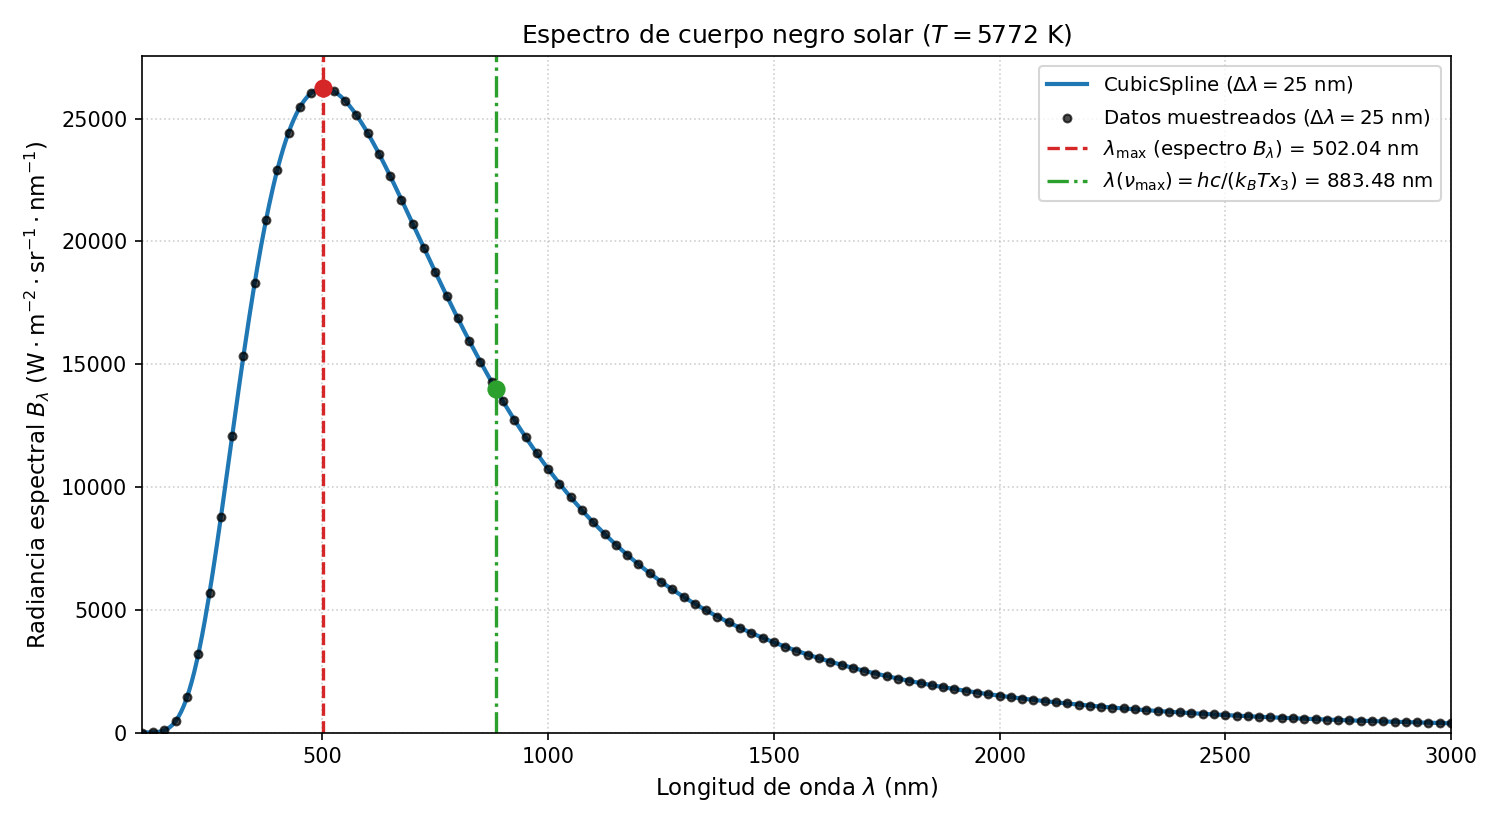

In [54]:
from IPython.display import Image, display
display(Image('espectro_solar.png'))